# Cáncer de origen primario desconocido (CUP) vs. cánceres metastásicos de primario conocido
**Egresos hospitalarios GRD 2019–2025 · Análisis de Datos e Inferencia Estadística**

Integrantes: Bastián Campos · Maximiliano Mella · Agustín Tapia

**Pregunta:** ¿los pacientes con CUP tienen peores resultados hospitalarios (mortalidad, estancia, severidad GRD y uso de recursos) que los pacientes con cáncer metastásico de primario conocido?

**Cómo correrlo en VS Code**
1. Abrir este archivo y elegir el kernel de Python (arriba a la derecha).
2. Los `GRD20XX.txt` (y `GRD_PUBLICO_2019.txt`, `GRD_PUBLICO_2025.txt`) deben estar en `BD/GRD_C80/` (junto a este notebook), o el comprimido en `BD/GRD_C80.rar`. En la celda 0, las líneas que imprime deben decir `True` (al menos el .rar o la carpeta). Si el notebook se abre desde otra ubicación, cambiar `CARPETA_PROYECTO`.
3. Requiere `pyarrow` para el .parquet (`pip install pyarrow`).
4. Usar **Run All** (ejecutar todo, en orden). Si ya existe la base `BD/GRD_grupos_estudio_2019_2025.parquet` tarda segundos; si no, la extracción tarda unos minutos.

## 0. Librerías y configuración

In [1]:
import io
import subprocess
import datetime as dt
import collections
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    import pyarrow  # noqa: F401  (pandas lo usa para leer y escribir .parquet)
except ImportError:
    raise ImportError('Falta pyarrow para leer la base .parquet: ejecutar  pip install pyarrow  '
                      'en la terminal y reiniciar el kernel.')

# >>> Carpeta donde está este notebook (VS Code/Jupyter la usan como directorio de trabajo).
#     Si no corresponde, poner la ruta completa, p. ej. Path(r'C:\UDD\2026_S2\Analisis Datos\Proyecto') <<<
CARPETA_PROYECTO = Path.cwd()

RUTA_RAR = CARPETA_PROYECTO / 'BD' / 'GRD_C80.rar'                     # comprimido con los GRD20XX.txt
RUTA_TXT = CARPETA_PROYECTO / 'BD' / 'GRD_C80'                         # alternativa: .txt descomprimidos
ANIOS = range(2019, 2026)              # años GRD incluidos (2019-2025)
ARCHIVO_GRUPOS = CARPETA_PROYECTO / 'BD' / f'GRD_grupos_estudio_{ANIOS[0]}_{ANIOS[-1]}.parquet'
EDAD_MINIMA = 18                       # solo adultos
REHACER_EXTRACCION = False             # True = volver a leer los .txt aunque ya exista el .parquet

print('Carpeta del proyecto:       ', CARPETA_PROYECTO)
print('Carpeta del proyecto existe:', CARPETA_PROYECTO.exists())
print('GRD_C80.rar encontrado:     ', RUTA_RAR.exists())
print('Carpeta GRD_C80 encontrada: ', RUTA_TXT.exists())
print('Base .parquet encontrada:    ', ARCHIVO_GRUPOS.exists())

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

Carpeta del proyecto:        C:\UDD\2026_S2\Analisis Datos\Proyecto
Carpeta del proyecto existe: True
GRD_C80.rar encontrado:      False
Carpeta GRD_C80 encontrada:  True
Base .parquet encontrada:     True


## 1. Grupos de estudio

| Grupo | Diagnóstico | Código CIE-10 del tumor primario |
|---|---|---|
| 1 | Cáncer de origen primario desconocido (CUP) | C80.0 |
| 2 | Cáncer de pulmón metastásico | C34 |
| 3 | Cáncer colorrectal metastásico | C18–C20 |
| 4 | Cáncer de mama metastásico | C50 |
| 5 | Cáncer de próstata metastásico | C61 |
| 6 | Cáncer gástrico metastásico | C16 |

**Reglas usadas** (los códigos se buscan en los 35 diagnósticos):
- *Metastásico* = el egreso tiene además un código de metástasis **C77, C78 o C79**.
- Los grupos 2–6 no pueden tener C80.
- Se excluyen: egresos con más de uno de los 5 primarios, egresos con C80.0 **y** alguno de los 5 primarios (contradictorio) y menores de 18 años (el análisis es solo en adultos).

**Problemas de formato de los archivos** que se corrigen al leer: cada año tiene distinta codificación (UTF-8, UTF-16, latin-1), 2023 trae fechas DD-MM-AAAA, 2024 llama `ID_BENEFICIARIO` al ID del paciente, 2022 tiene 1 fila con 130 campos, y el peso GRD usa coma decimal. 2019 y 2025 se llaman `GRD_PUBLICO_AAAA.txt`. **2025 no trae fecha de nacimiento ni comuna**: solo `TRAMO_EDAD` en tramos de 5 años, así que su edad es el punto medio del tramo (p. ej. 80–84 → 82,5) y el tramo 15–19 se excluye completo (no se puede separar a los de 18 y 19). La columna `EDAD_ORIGEN` indica de dónde salió la edad de cada egreso.

In [2]:
ENCODING = {2019: 'utf-8', 2020: 'utf-8', 2021: 'utf-8-sig', 2022: 'utf-16', 2023: 'utf-16',
            2024: 'cp1252', 2025: 'utf-8'}
PRIMARIOS = {'Pulmón': {'C34'}, 'Colorrectal': {'C18', 'C19', 'C20'}, 'Mama': {'C50'},
             'Próstata': {'C61'}, 'Gástrico': {'C16'}}
METASTASIS = {'C77', 'C78', 'C79'}
ORDEN = ['CUP', 'Pulmón', 'Colorrectal', 'Mama', 'Próstata', 'Gástrico']
FECHAS = ['FECHA_NACIMIENTO', 'FECHA_INGRESO', 'FECHAALTA', 'FECHAINTERV1', 'FECHAPROCEDIMIENTO1'] + \
         [f'FECHATRASLADO{i}' for i in range(1, 10)]


def fecha_iso(s):
    """Deja todas las fechas en AAAA-MM-DD (2023 viene en DD-MM-AAAA)."""
    s = s.strip()[:10]
    for fmt in ('%Y-%m-%d', '%d-%m-%Y'):
        try:
            return dt.datetime.strptime(s, fmt).date().isoformat()
        except ValueError:
            pass
    return ''


def clasificar(codigos):
    """Devuelve (grupo, motivo_exclusion) para la lista de diagnósticos de un egreso."""
    c3 = {c[:3] for c in codigos}
    primarios = [g for g, cods in PRIMARIOS.items() if c3 & cods]
    if any(c.startswith('C80.0') for c in codigos):
        return (None, 'C80.0 con primario conocido') if primarios else ('CUP', None)
    if not primarios or 'C80' in c3 or not (c3 & METASTASIS):
        return None, None
    if len(primarios) > 1:
        return None, 'más de un primario'
    return primarios[0], None


def abrir_anio(anio):
    """Abre el GRD del año desde la carpeta (GRD2020.txt o GRD_PUBLICO_2019.txt) o directo desde el .rar."""
    nombres = [f'GRD{anio}.txt', f'GRD_PUBLICO_{anio}.txt']
    for nombre in nombres:
        if (RUTA_TXT / nombre).exists():
            return open(RUTA_TXT / nombre, encoding=ENCODING[anio], errors='replace', newline=''), None
    if not RUTA_RAR.exists():
        raise FileNotFoundError(f'No se encontró {" ni ".join(nombres)} en {RUTA_TXT} ni {RUTA_RAR}. '
                                'Revisa CARPETA_PROYECTO en la celda 0.')
    p = subprocess.Popen(['tar', '-xOf', str(RUTA_RAR), f'GRD_C80/{nombres[0]}'], stdout=subprocess.PIPE)
    return io.TextIOWrapper(p.stdout, encoding=ENCODING[anio], errors='replace', newline=''), p


## 2. Extracción de los grupos
Se leen los ~6,94 millones de egresos línea por línea y solo se guardan los que pertenecen a algún grupo.

In [3]:
def edad_desde_tramo(tramo):
    """'[80 - 84 años]' -> (80, 82.5): inicio del tramo y su punto medio. 2025 no trae fecha de nacimiento."""
    numeros = re.findall(r'\d+', tramo)
    if len(numeros) < 2:
        return None, None
    desde, hasta = int(numeros[0]), int(numeros[1])
    return desde, (desde + hasta + 1) / 2


def extraer(anio, excluidos):
    f, proc = abrir_anio(anio)
    header = f.readline().rstrip('\r\n').lstrip('\ufeff').split('|')
    header = ['CIP_ENCRIPTADO' if c == 'ID_BENEFICIARIO' else c for c in header]
    if 'DIAGNOSTICO1' not in header:
        raise ValueError(f'GRD{anio}: no se pudo leer el encabezado. Revisa que el archivo exista y no esté dañado.')
    diag = [header.index(f'DIAGNOSTICO{i}') for i in range(1, 36)]
    fechas = [c for c in FECHAS if c in header]
    filas, total = [], 0
    for line in f:
        v = line.rstrip('\r\n').split('|')
        if len(v) != len(header):            # fila mal formada de 2022
            continue
        total += 1
        codigos = [v[j].strip().upper() for j in diag if v[j].strip()]
        grupo, motivo = clasificar(codigos)
        if motivo:
            excluidos[motivo] += 1
        if not grupo:
            continue
        fila = {k: ('' if x.strip().upper() == 'DESCONOCIDO' else x.strip()) for k, x in zip(header, v)}
        for c in fechas:
            fila[c] = fecha_iso(fila[c])
        edad, origen = None, ''
        if fila.get('FECHA_NACIMIENTO') and fila['FECHA_INGRESO']:
            edad = (dt.date.fromisoformat(fila['FECHA_INGRESO']) - dt.date.fromisoformat(fila['FECHA_NACIMIENTO'])).days / 365.25
            origen = 'fecha de nacimiento'
        elif fila.get('TRAMO_EDAD'):
            desde, edad = edad_desde_tramo(fila['TRAMO_EDAD'])
            origen = 'punto medio del tramo'
            if desde is not None and desde < EDAD_MINIMA:     # el tramo 15-19 se excluye completo
                edad = 0
        if edad is not None and edad < EDAD_MINIMA:
            excluidos[f'menor de {EDAD_MINIMA} años'] += 1
            continue
        peso = fila['IR_29301_PESO'].replace(',', '.')
        fila['IR_29301_PESO'] = '0' + peso if peso.startswith('.') else peso
        fila['ANIO'], fila['GRUPO'] = anio, grupo
        fila['EDAD'], fila['EDAD_ORIGEN'] = (round(edad, 2) if edad is not None else None), origen
        filas.append(fila)
    f.close()
    if proc:
        proc.wait()
    return header, filas, total


if 'REHACER_EXTRACCION' not in globals() or 'clasificar' not in globals():
    raise RuntimeError('Primero ejecuta las celdas anteriores (0 y 1). Lo más simple: botón "Run All".')

if REHACER_EXTRACCION or not ARCHIVO_GRUPOS.exists():
    todas, excluidos, totales, columnas = [], collections.Counter(), {}, ['ANIO', 'GRUPO', 'EDAD', 'EDAD_ORIGEN']
    for anio in ANIOS:
        cols, filas, totales[anio] = extraer(anio, excluidos)
        columnas += [c for c in cols if c not in columnas]     # 2025 trae TRAMO_EDAD y no FECHA_NACIMIENTO ni COMUNA
        todas += filas
        print(f'{anio}: {totales[anio]:,} egresos leídos -> {len(filas):,} en los grupos')
    base = pd.DataFrame(todas, columns=columnas)
    texto = base.columns.difference(['ANIO', 'EDAD'])
    base[texto] = base[texto].replace('', None)               # vacío = dato faltante (como al leer el CSV)
    base['ANIO'] = base['ANIO'].astype('int16')
    base['EDAD'] = base['EDAD'].astype(float)
    ARCHIVO_GRUPOS.parent.mkdir(parents=True, exist_ok=True)
    base.to_parquet(ARCHIVO_GRUPOS, index=False)
    print('\nTotal egresos leídos:', f'{sum(totales.values()):,}')
    print('Excluidos:', dict(excluidos))
    print('Guardado en', ARCHIVO_GRUPOS)
    del todas, base
else:
    print(f'Usando la base ya generada: {ARCHIVO_GRUPOS} (para rehacerla, poner REHACER_EXTRACCION = True)')


Usando la base ya generada: C:\UDD\2026_S2\Analisis Datos\Proyecto\BD\GRD_grupos_estudio_2019_2025.parquet (para rehacerla, poner REHACER_EXTRACCION = True)


## 3. Preparación: variables derivadas

In [4]:
df = pd.read_parquet(ARCHIVO_GRUPOS)
for c in ['FECHA_NACIMIENTO', 'FECHA_INGRESO', 'FECHAALTA']:
    df[c] = pd.to_datetime(df[c], errors='coerce')

df['ANIO'] = df['ANIO'].astype(int)
df['GRUPO'] = pd.Categorical(df['GRUPO'], ORDEN)
df['EDAD'] = df['EDAD'].astype(float)        # exacta 2019-2024; punto medio del tramo en 2025
df['DIAS_ESTADA'] = (df['FECHAALTA'] - df['FECHA_INGRESO']).dt.days
df['PESO_GRD'] = pd.to_numeric(df['IR_29301_PESO'], errors='coerce')
df['SEVERIDAD'] = pd.to_numeric(df['IR_29301_SEVERIDAD'], errors='coerce')
df['FALLECIDO'] = (df['TIPOALTA'] == 'FALLECIDO').astype(int)
df['SEV3'] = (df['SEVERIDAD'] == 3).astype(int)
df['URGENCIA'] = (df['TIPO_INGRESO'] == 'URGENCIA').astype(int)
df['MUJER'] = (df['SEXO'] == 'MUJER').astype(int)
df['USO_PABELLON'] = (pd.to_numeric(df['USOSPABELLON'], errors='coerce').fillna(0) > 0).astype(int)
df['N_PROCEDIMIENTOS'] = df[[f'PROCEDIMIENTO{i}' for i in range(1, 31)]].notna().sum(axis=1)

print(f'{len(df):,} egresos | {df.CIP_ENCRIPTADO.nunique():,} pacientes')
df[['ANIO', 'GRUPO', 'SEXO', 'EDAD', 'DIAS_ESTADA', 'TIPO_INGRESO', 'TIPOALTA', 'SEVERIDAD', 'PESO_GRD']].head()

60,816 egresos | 41,305 pacientes


,ANIO,GRUPO,SEXO,EDAD,DIAS_ESTADA,TIPO_INGRESO,TIPOALTA,SEVERIDAD,PESO_GRD
0,2019,Gástrico,HOMBRE,64.75,25,URGENCIA,DOMICILIO,2.0,0.7994
1,2019,Colorrectal,HOMBRE,82.17,14,URGENCIA,DOMICILIO,2.0,0.7000
2,2019,Colorrectal,MUJER,63.85,1,PROGRAMADA,DOMICILIO,2.0,0.9168
3,2019,Próstata,HOMBRE,70.48,2,URGENCIA,DERIVACIÓN OTRO HOSPITAL DEL SERVICIO,2.0,0.7700
4,2019,Pulmón,MUJER,60.47,7,URGENCIA,FALLECIDO,3.0,1.3157


## 4. Descripción de los datos
### 4.1 Egresos por grupo y año

In [5]:
tabla_n = pd.crosstab(df['GRUPO'], df['ANIO'], margins=True, margins_name='Total')
tabla_n['Pacientes'] = df.groupby('GRUPO', observed=True)['CIP_ENCRIPTADO'].nunique().reindex(tabla_n.index)
tabla_n.loc['Total', 'Pacientes'] = df['CIP_ENCRIPTADO'].nunique()
tabla_n

ANIO,2019,2020,2021,2022,2023,2024,2025,Total,Pacientes
GRUPO,,,,,,,,,
CUP,622,473,479,508,559,597,651,3889,3520.0
Pulmón,1378,968,868,1030,1376,1407,1679,8706,6768.0
Colorrectal,3235,2259,2329,2517,2973,3436,3832,20581,11968.0
Mama,2511,1219,1202,1478,1899,1996,2215,12520,8285.0
Próstata,954,647,708,767,1017,1210,1381,6684,4995.0
Gástrico,1201,1062,1092,1127,1218,1274,1462,8436,6124.0
Total,9901,6628,6678,7427,9042,9920,11220,60816,41305.0


**Lectura de la tabla:** 2020 y 2021 tienen menos egresos que 2019 en todos los grupos: es el efecto de la pandemia de COVID-19, que postergó hospitalizaciones (sobre todo las programadas; mama cae de 2.511 a 1.219). Desde 2022 los egresos se recuperan y en 2025 superan a 2019 en todos los grupos salvo mama. Por eso los cambios en el tiempo se miden desde 2019, el último año antes de la pandemia.

La columna *Pacientes* es aproximada: el ID cifrado cambia entre 2020 y 2021 (ningún paciente coincide entre esos dos años), así que quien se hospitalizó a ambos lados de ese corte se cuenta dos veces.

### 4.2 Datos faltantes en variables clave

In [6]:
clave = ['SEXO', 'EDAD', 'PREVISION', 'SERVICIO_SALUD', 'TIPO_INGRESO', 'FECHA_INGRESO',
         'FECHAALTA', 'TIPOALTA', 'IR_29301_COD_GRD', 'IR_29301_PESO', 'IR_29301_SEVERIDAD', 'HOSPPROCEDENCIA']
faltantes = pd.DataFrame({'n faltantes': df[clave].isna().sum(), '% faltante': (df[clave].isna().mean() * 100).round(2)})
faltantes

,n faltantes,% faltante
SEXO,5,0.01
EDAD,0,0.00
PREVISION,0,0.00
SERVICIO_SALUD,1,0.00
TIPO_INGRESO,1,0.00
FECHA_INGRESO,0,0.00
FECHAALTA,0,0.00
TIPOALTA,0,0.00
IR_29301_COD_GRD,1,0.00
IR_29301_PESO,1,0.00


Las variables clave están prácticamente completas. `HOSPPROCEDENCIA` está vacía en la mayoría de los egresos porque solo se llena cuando el paciente viene derivado de otro hospital; no es un error.

### 4.3 Valores atípicos en la estancia (regla 1,5 × RIC)

In [7]:
def atipicos(s):
    q1, q3 = s.quantile([.25, .75])
    lim = q3 + 1.5 * (q3 - q1)
    return pd.Series({'límite superior (días)': lim, 'n atípicos': (s > lim).sum(),
                      '% atípicos': round((s > lim).mean() * 100, 1), 'máximo': s.max()})

df.groupby('GRUPO', observed=True)['DIAS_ESTADA'].apply(atipicos).unstack()

,límite superior (días),n atípicos,% atípicos,máximo
GRUPO,,,,
CUP,38.0,186.0,4.8,371.0
Pulmón,30.5,525.0,6.0,118.0
Colorrectal,19.5,1970.0,9.6,369.0
Mama,16.0,1146.0,9.2,422.0
Próstata,29.5,410.0,6.1,447.0
Gástrico,27.0,580.0,6.9,248.0


Las estancias largas son clínicamente posibles (complicaciones, cuidados paliativos), así que **se mantienen** en el análisis. Por la fuerte asimetría se reportan **medianas y RIC** en vez de promedios.

## 5. Comparación de resultados hospitalarios

In [8]:
def med_ric(s):
    q1, m, q3 = s.quantile([.25, .5, .75])
    return f'{m:.0f} [{q1:.0f}–{q3:.0f}]'

resumen = df.groupby('GRUPO', observed=True).agg(
    Egresos=('FALLECIDO', 'size'),
    Edad_mediana=('EDAD', 'median'),
    Mujeres_pct=('MUJER', 'mean'),
    Urgencia_pct=('URGENCIA', 'mean'),
    Mortalidad_pct=('FALLECIDO', 'mean'),
    Severidad3_pct=('SEV3', 'mean'),
    Pabellon_pct=('USO_PABELLON', 'mean'),
    Peso_GRD_media=('PESO_GRD', 'mean'),
)
for c in ['Mujeres_pct', 'Urgencia_pct', 'Mortalidad_pct', 'Severidad3_pct', 'Pabellon_pct']:
    resumen[c] = (resumen[c] * 100).round(1)
resumen['Edad_mediana'] = resumen['Edad_mediana'].round(0)
resumen['Peso_GRD_media'] = resumen['Peso_GRD_media'].round(2)
resumen.insert(5, 'Estancia_mediana_RIC', df.groupby('GRUPO', observed=True)['DIAS_ESTADA'].apply(med_ric))
resumen

,Egresos,Edad_mediana,Mujeres_pct,Urgencia_pct,Mortalidad_pct,Estancia_mediana_RIC,Severidad3_pct,Pabellon_pct,Peso_GRD_media
GRUPO,,,,,,,,,
CUP,3889,69.0,53.8,80.9,21.7,9 [3–17],50.8,27.7,1.39
Pulmón,8706,68.0,44.4,74.6,22.1,7 [3–14],51.2,22.8,1.34
Colorrectal,20581,65.0,48.5,49.1,7.7,4 [2–9],27.6,33.2,1.49
Mama,12520,59.0,99.3,45.6,9.1,3 [1–7],24.9,36.2,1.14
Próstata,6684,73.0,0.2,78.4,13.9,6 [2–13],45.4,23.1,1.21
Gástrico,8436,66.0,32.5,58.4,12.2,5 [2–12],35.8,31.9,1.38


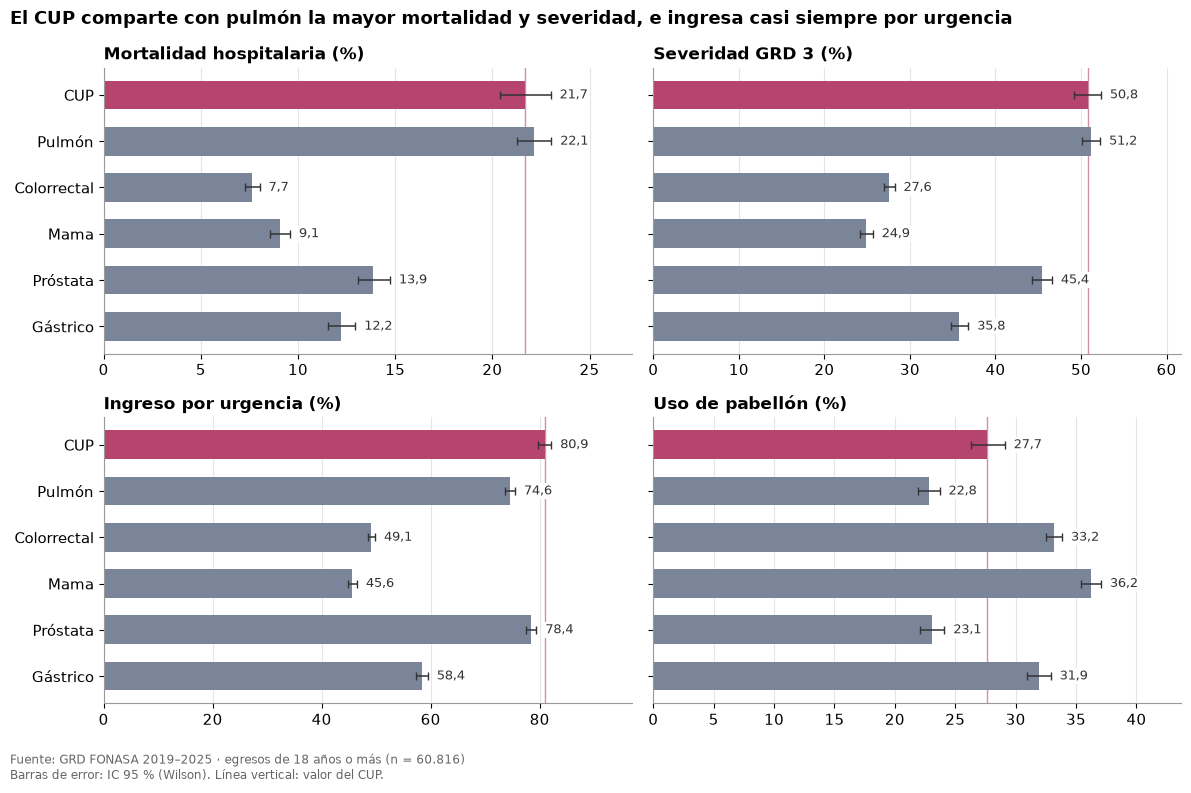

In [9]:
# Estilo común de las figuras (se guardan en la carpeta figuras/ para usarlas en la presentación)
CARPETA_FIG = CARPETA_PROYECTO / 'figuras'
CARPETA_FIG.mkdir(exist_ok=True)
COLOR_CUP, COLOR_OTRO, TINTA = '#B5446E', '#7A8599', '#333333'   # gris con contraste 3,7:1 sobre blanco
COLORES = [COLOR_CUP if g == 'CUP' else COLOR_OTRO for g in ORDEN]
FUENTE = f'Fuente: GRD FONASA {ANIOS[0]}–{ANIOS[-1]} · egresos de {EDAD_MINIMA} años o más (n = {len(df):,})'.replace(',', '.')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 11,
                     'axes.titlesize': 12, 'axes.edgecolor': '#999999', 'savefig.dpi': 200,
                     'savefig.bbox': 'tight'})


def coma(v, d=1):
    """Número con coma decimal."""
    return f'{v:.{d}f}'.replace('.', ',')


def ic_prop(x, n, z=1.96):
    """IC 95 % de Wilson para una proporción, en %."""
    x, n = np.asarray(x, float), np.asarray(n, float)
    p = x / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (centro - margen) * 100, (centro + margen) * 100


def cerrar(fig, nombre, titulo, nota=''):
    """Título con la conclusión, fuente al pie, guardado en PNG y despliegue."""
    fig.suptitle(titulo, x=0.01, ha='left', fontweight='bold', fontsize=13)
    fig.tight_layout()
    fig.text(0.01, -0.01, FUENTE + (f'\n{nota}' if nota else ''), fontsize=8.5, color='#666666',
             ha='left', va='top')
    fig.savefig(CARPETA_FIG / f'{nombre}.png')
    plt.show()


y = np.arange(len(ORDEN))[::-1]          # CUP arriba
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharey=True)
for ax, (var, titulo) in zip(axes.flat, [('FALLECIDO', 'Mortalidad hospitalaria (%)'),
                                         ('SEV3', 'Severidad GRD 3 (%)'),
                                         ('URGENCIA', 'Ingreso por urgencia (%)'),
                                         ('USO_PABELLON', 'Uso de pabellón (%)')]):
    agg = df.groupby('GRUPO', observed=True)[var].agg(['sum', 'size']).loc[ORDEN]
    pct = agg['sum'] / agg['size'] * 100
    lo, hi = ic_prop(agg['sum'], agg['size'])
    ax.barh(y, pct, color=COLORES, height=.62)
    ax.errorbar(pct, y, xerr=[pct - lo, hi - pct], fmt='none', ecolor=TINTA, elinewidth=1.1, capsize=3)
    ax.axvline(pct['CUP'], color=COLOR_CUP, lw=1, alpha=.6, zorder=0)
    for yi, v, h in zip(y, pct, hi):
        ax.text(h + hi.max() * .02, yi, coma(v), va='center', fontsize=9.5, color=TINTA,
                bbox=dict(facecolor='white', edgecolor='none', pad=1))
    ax.set_yticks(y, ORDEN)
    ax.set_xlim(0, hi.max() * 1.18)
    ax.set_title(titulo, loc='left', fontweight='bold')
    ax.grid(axis='x', color='#e5e5e5')
    ax.set_axisbelow(True)
cerrar(fig, '01_indicadores_por_grupo',
       'El CUP comparte con pulmón la mayor mortalidad y severidad, e ingresa casi siempre por urgencia',
       'Barras de error: IC 95 % (Wilson). Línea vertical: valor del CUP.')

**Interpretación** (las barras de error son el IC 95 %; si dos intervalos no se tocan, la diferencia es clara)
- **Mortalidad:** el CUP (21,7 %) tiene una mortalidad hospitalaria cuyo intervalo se superpone con el del cáncer de pulmón metastásico (22,1 %), y es claramente mayor que la de colorrectal, mama, gástrico y próstata.
- **Severidad y urgencia:** la mitad de los egresos CUP tienen severidad GRD 3 y más del 80 % ingresa por urgencia, igual que pulmón y próstata y muy por sobre colorrectal y mama (≈50 %). Esto sugiere que el CUP suele detectarse en una descompensación aguda.
- **Pabellón:** el CUP usa menos pabellón que los cánceres que se tratan con cirugía (mama 36 %, colorrectal 33 %, gástrico 32 %, frente a 28 % en el CUP).

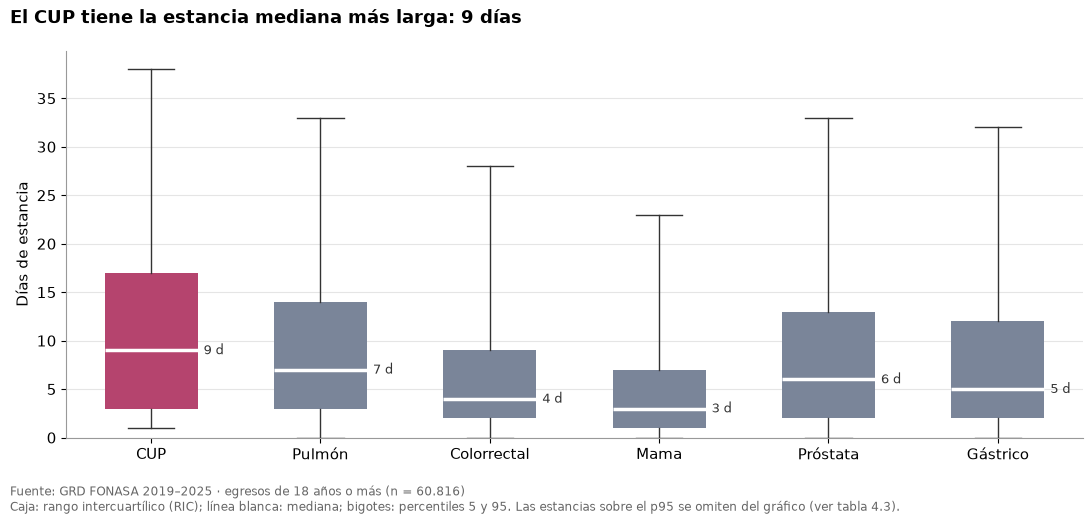

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.8))
datos = [df.loc[df.GRUPO == g, 'DIAS_ESTADA'].dropna() for g in ORDEN]
bp = ax.boxplot(datos, tick_labels=ORDEN, patch_artist=True, widths=.55, whis=(5, 95), showfliers=False,
                medianprops=dict(color='white', linewidth=2.5),
                whiskerprops=dict(color=TINTA), capprops=dict(color=TINTA))
for caja, color in zip(bp['boxes'], COLORES):
    caja.set_facecolor(color)
    caja.set_edgecolor('none')
for i, d in enumerate(datos, start=1):
    ax.text(i + .31, d.median(), f'{d.median():.0f} d', va='center', fontsize=9.5, color=TINTA)
ax.set_ylim(0, None)
ax.set_ylabel('Días de estancia')
ax.grid(axis='y', color='#e5e5e5')
ax.set_axisbelow(True)
cerrar(fig, '02_estancia_por_grupo', 'El CUP tiene la estancia mediana más larga: 9 días',
       'Caja: rango intercuartílico (RIC); línea blanca: mediana; bigotes: percentiles 5 y 95. '
       'Las estancias sobre el p95 se omiten del gráfico (ver tabla 4.3).')

**Interpretación:** el CUP tiene la **estancia mediana más larga** de todos los grupos (9 días [RIC 3–17], frente a 3 en mama, 4 en colorrectal y 5 en gástrico) y también la caja más alta: una cuarta parte de sus egresos supera los 17 días. Como usa menos pabellón, la estancia se explicaría más por días de cama (estudio para buscar el tumor primario, manejo de complicaciones) que por cirugías.

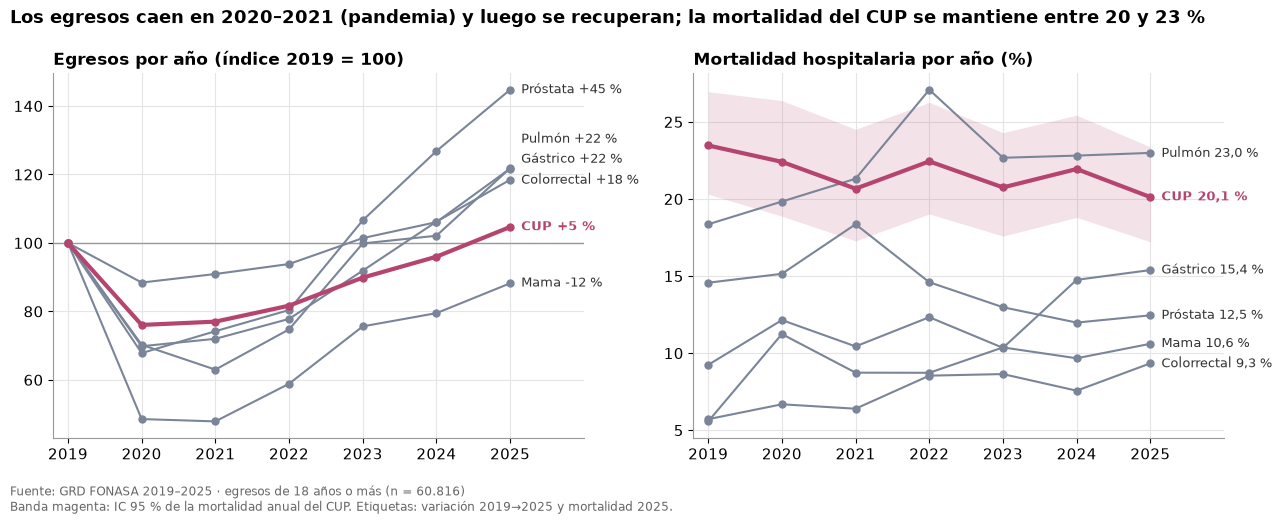

In [11]:
anual = df.groupby(['ANIO', 'GRUPO'], observed=True).agg(egresos=('FALLECIDO', 'size'),
                                                         muertes=('FALLECIDO', 'sum')).reset_index()
anual['mortalidad'] = anual.muertes / anual.egresos * 100
anual['indice'] = anual.egresos / anual.groupby('GRUPO', observed=True).egresos.transform('first') * 100


def rotular_finales(ax, finales, separacion, texto):
    """Etiqueta el último punto de cada línea sin que los textos se encimen."""
    ultimo = None
    for g, v in sorted(finales.items(), key=lambda kv: kv[1]):
        y_txt = v if ultimo is None else max(v, ultimo + separacion)
        ax.annotate(texto(g, v), xy=(ANIOS[-1], v), xytext=(ANIOS[-1] + .15, y_txt), va='center', fontsize=9,
                    color=COLOR_CUP if g == 'CUP' else TINTA, fontweight='bold' if g == 'CUP' else 'normal')
        ultimo = y_txt


fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for g, color in zip(ORDEN, COLORES):
    d = anual[anual.GRUPO == g]
    kw = dict(color=color, linewidth=3 if g == 'CUP' else 1.5, marker='o', markersize=5,
              zorder=3 if g == 'CUP' else 2)
    axes[0].plot(d.ANIO, d.indice, **kw)
    axes[1].plot(d.ANIO, d.mortalidad, **kw)
    if g == 'CUP':
        lo, hi = ic_prop(d.muertes, d.egresos)
        axes[1].fill_between(d.ANIO, lo, hi, color=COLOR_CUP, alpha=.15, linewidth=0)

fin = anual[anual.ANIO == ANIOS[-1]].set_index('GRUPO')
rotular_finales(axes[0], fin['indice'].to_dict(), 6, lambda g, v: f'{g} {v - 100:+.0f} %')
rotular_finales(axes[1], fin['mortalidad'].to_dict(), 1.2, lambda g, v: f'{g} {coma(v)} %')
axes[0].axhline(100, color='#999999', lw=1, zorder=1)
axes[0].set_title(f'Egresos por año (índice {ANIOS[0]} = 100)', loc='left', fontweight='bold')
axes[1].set_title('Mortalidad hospitalaria por año (%)', loc='left', fontweight='bold')
for ax in axes:
    ax.set_xticks(list(ANIOS))
    ax.set_xlim(ANIOS[0] - .2, ANIOS[-1] + 1)
    ax.grid(color='#e5e5e5')
    ax.set_axisbelow(True)
cerrar(fig, '03_evolucion_anual',
       'Los egresos caen en 2020–2021 (pandemia) y luego se recuperan; la mortalidad del CUP se mantiene '
       f'entre {anual[anual.GRUPO == "CUP"].mortalidad.min():.0f} y {anual[anual.GRUPO == "CUP"].mortalidad.max():.0f} %',
       f'Banda magenta: IC 95 % de la mortalidad anual del CUP. Etiquetas: variación {ANIOS[0]}→{ANIOS[-1]} '
       f'y mortalidad {ANIOS[-1]}.')

### 5.1 ¿El CUP muere más solo porque llega más grave o más viejo?
Se compara la mortalidad **dentro de cada nivel de severidad GRD** y **dentro de cada tramo de edad**. Si el CUP sigue arriba a igual severidad o edad, su mayor mortalidad no se explica solo por esas variables. La severidad 0 (GRD sin nivel de severidad, casi sin fallecidos) se agrupa con la 1 como "baja".

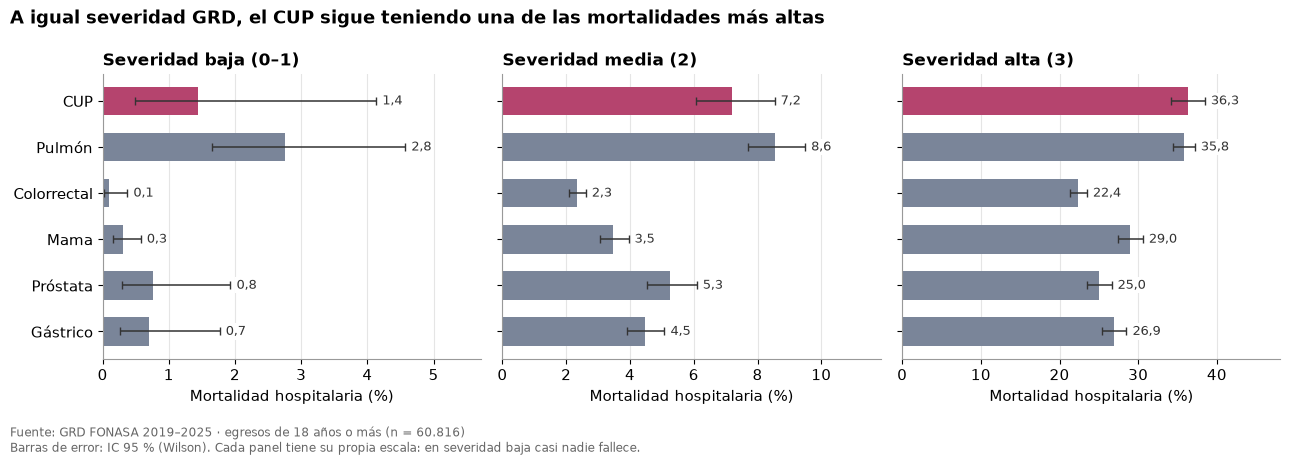

In [12]:
df['SEV_CAT'] = df['SEVERIDAD'].clip(lower=1)
niveles = [(1, 'Severidad baja (0–1)'), (2, 'Severidad media (2)'), (3, 'Severidad alta (3)')]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, (nivel, titulo) in zip(axes, niveles):
    agg = df[df.SEV_CAT == nivel].groupby('GRUPO', observed=True)['FALLECIDO'].agg(['sum', 'size']).loc[ORDEN]
    pct = agg['sum'] / agg['size'] * 100
    lo, hi = ic_prop(agg['sum'], agg['size'])
    ax.barh(y, pct, color=COLORES, height=.62)
    ax.errorbar(pct, y, xerr=[pct - lo, hi - pct], fmt='none', ecolor=TINTA, elinewidth=1.1, capsize=3)
    for yi, v, h in zip(y, pct, hi):
        ax.text(h + hi.max() * .02, yi, coma(v), va='center', fontsize=9.5, color=TINTA,
                bbox=dict(facecolor='white', edgecolor='none', pad=1))
    ax.set_yticks(y, ORDEN)
    ax.set_xlim(0, hi.max() * 1.25)
    ax.set_title(titulo, loc='left', fontweight='bold')
    ax.set_xlabel('Mortalidad hospitalaria (%)')
    ax.grid(axis='x', color='#e5e5e5')
    ax.set_axisbelow(True)
cerrar(fig, '04_mortalidad_por_severidad',
       'A igual severidad GRD, el CUP sigue teniendo una de las mortalidades más altas',
       'Barras de error: IC 95 % (Wilson). Cada panel tiene su propia escala: en severidad baja casi nadie fallece.')

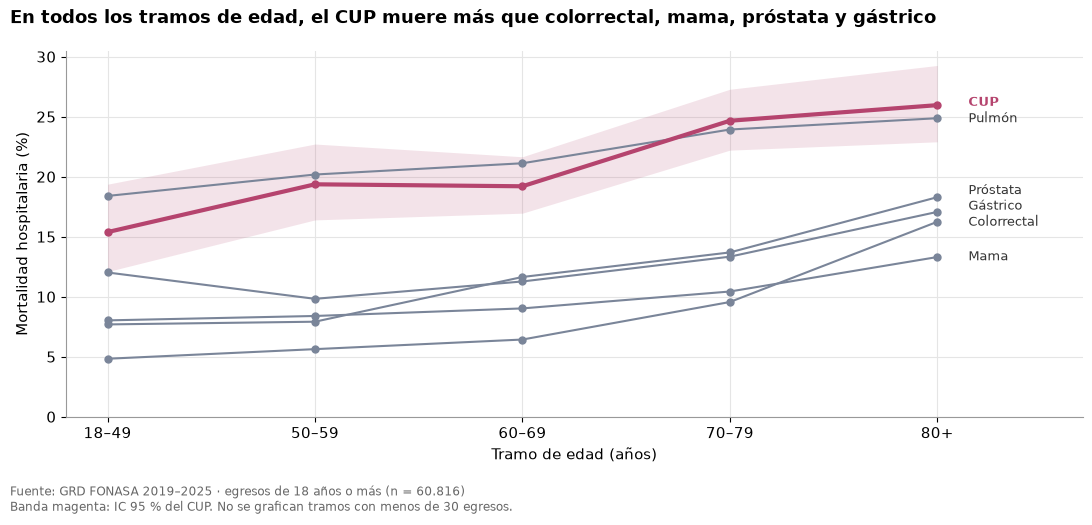

In [13]:
TRAMOS = ['18–49', '50–59', '60–69', '70–79', '80+']
df['TRAMO_EDAD'] = pd.cut(df['EDAD'], [18, 50, 60, 70, 80, 200], right=False, labels=TRAMOS)
N_MIN = 30                                  # celdas con menos egresos no se grafican (muy inestables)
edad = df.groupby(['GRUPO', 'TRAMO_EDAD'], observed=True)['FALLECIDO'].agg(['mean', 'size']).reset_index()
omitidos = [f'{g.lower()} {t}' for g, t, n in edad[['GRUPO', 'TRAMO_EDAD', 'size']].itertuples(index=False) if n < N_MIN]
edad = edad[edad['size'] >= N_MIN]

fig, ax = plt.subplots(figsize=(11, 4.8))
x = {t: i for i, t in enumerate(TRAMOS)}
finales = {}
for g, color in zip(ORDEN, COLORES):
    d = edad[edad.GRUPO == g]
    xs, ys = d.TRAMO_EDAD.map(x).astype(float), d['mean'] * 100
    ax.plot(xs, ys, color=color, linewidth=3 if g == 'CUP' else 1.5, marker='o', markersize=5,
            zorder=3 if g == 'CUP' else 2)
    finales[g] = ys.iloc[-1]
    if g == 'CUP':
        cnt = df[df.GRUPO == 'CUP'].groupby('TRAMO_EDAD', observed=True)['FALLECIDO'].agg(['sum', 'size']).loc[TRAMOS]
        lo, hi = ic_prop(cnt['sum'], cnt['size'])
        ax.fill_between(range(len(TRAMOS)), lo, hi, color=COLOR_CUP, alpha=.15, linewidth=0)
ultimo = None
for g, v in sorted(finales.items(), key=lambda kv: kv[1]):
    y_txt = v if ultimo is None else max(v, ultimo + 1.3)
    ax.annotate(g, xy=(len(TRAMOS) - 1, v), xytext=(len(TRAMOS) - .85, y_txt), va='center', fontsize=9,
                color=COLOR_CUP if g == 'CUP' else TINTA, fontweight='bold' if g == 'CUP' else 'normal')
    ultimo = y_txt
ax.set_xticks(range(len(TRAMOS)), TRAMOS)
ax.set_xlim(-.2, len(TRAMOS) - .3)
ax.set_ylim(0, None)
ax.set_xlabel('Tramo de edad (años)')
ax.set_ylabel('Mortalidad hospitalaria (%)')
ax.grid(color='#e5e5e5')
ax.set_axisbelow(True)
cerrar(fig, '05_mortalidad_por_edad',
       'En todos los tramos de edad, el CUP muere más que colorrectal, mama, próstata y gástrico',
       f'Banda magenta: IC 95 % del CUP. No se grafican tramos con menos de {N_MIN} egresos'
       + (f' ({", ".join(omitidos)}).' if omitidos else '.'))

## 6. Pruebas estadísticas
### 6.1 Diferencias entre los 6 grupos

In [14]:
filas = []
for v, nombre in [('FALLECIDO', 'Mortalidad'), ('SEV3', 'Severidad 3'), ('URGENCIA', 'Ingreso urgencia'),
                  ('USO_PABELLON', 'Uso de pabellón')]:
    chi2, p, gl = stats.chi2_contingency(pd.crosstab(df['GRUPO'], df[v]))[:3]
    filas.append([nombre, 'Chi-cuadrado', round(chi2, 1), gl, p])
for v, nombre in [('DIAS_ESTADA', 'Estancia'), ('PESO_GRD', 'Peso GRD'), ('EDAD', 'Edad')]:
    h, p = stats.kruskal(*[d[v].dropna() for _, d in df.groupby('GRUPO', observed=True)])
    filas.append([nombre, 'Kruskal-Wallis', round(h, 1), 5, p])
pd.DataFrame(filas, columns=['Variable', 'Prueba', 'Estadístico', 'gl', 'p'])

,Variable,Prueba,Estadístico,gl,p
0,Mortalidad,Chi-cuadrado,1654.9,5,0.000000e+00
1,Severidad 3,Chi-cuadrado,2807.1,5,0.000000e+00
2,Ingreso urgencia,Chi-cuadrado,4428.6,5,0.000000e+00
3,Uso de pabellón,Chi-cuadrado,699.2,5,7.374457e-149
4,Estancia,Kruskal-Wallis,3431.9,5,0.000000e+00
5,Peso GRD,Kruskal-Wallis,2006.1,5,0.000000e+00
6,Edad,Kruskal-Wallis,6340.2,5,0.000000e+00


Todas las variables difieren significativamente entre los grupos (p < 0,001). Para saber **dónde** está la diferencia se compara el CUP contra cada grupo.

### 6.2 CUP vs. cada grupo (corrección de Bonferroni, 5 comparaciones)

In [15]:
cup = df[df.GRUPO == 'CUP']
filas = []
for g in ORDEN[1:]:
    otro = df[df.GRUPO == g]
    fila = {'Grupo': g}
    for v, nombre in [('FALLECIDO', 'Mortalidad'), ('SEV3', 'Severidad 3'), ('URGENCIA', 'Urgencia')]:
        par = pd.concat([cup, otro])
        p = stats.chi2_contingency(pd.crosstab(par['GRUPO'].astype(str), par[v]))[1]
        fila[f'{nombre}: dif. (pp)'] = round((cup[v].mean() - otro[v].mean()) * 100, 1)
        fila[f'{nombre}: p'] = min(p * 5, 1)
    p = stats.mannwhitneyu(cup['DIAS_ESTADA'], otro['DIAS_ESTADA'])[1]
    fila['Estancia: mediana CUP vs grupo'] = f"{cup['DIAS_ESTADA'].median():.0f} vs {otro['DIAS_ESTADA'].median():.0f}"
    fila['Estancia: p'] = min(p * 5, 1)
    filas.append(fila)

comparacion = pd.DataFrame(filas).set_index('Grupo')
comparacion.style.format({c: '{:.3g}' for c in comparacion.columns if c.endswith(': p')})

,Mortalidad: dif. (pp),Mortalidad: p,Severidad 3: dif. (pp),Severidad 3: p,Urgencia: dif. (pp),Urgencia: p,Estancia: mediana CUP vs grupo,Estancia: p
Grupo,,,,,,,,
Pulmón,-0.500000,1,-0.400000,1,6.400000,4.7e-14,9 vs 7,1.08e-12
Colorrectal,14.000000,4.46e-158,23.200000,7.49e-179,31.800000,1.1e-290,9 vs 4,5.18e-163
Mama,12.600000,1.09e-97,25.900000,9.71e-203,35.300000,0,9 vs 3,0
Próstata,7.800000,2.86e-24,5.400000,5.98e-07,2.500000,0.0122,9 vs 6,5.42e-36
Gástrico,9.400000,4.62e-41,15.000000,5.99e-55,22.500000,1.26e-130,9 vs 5,2.25e-74


**Interpretación** (p ajustado < 0,05 = diferencia significativa; *dif.* = CUP menos el otro grupo, en puntos porcentuales):
- Frente a **colorrectal, mama, gástrico y próstata**, el CUP tiene **mayor mortalidad**, más severidad y estancia más larga, todo significativo.
- Frente a **pulmón**, la mortalidad y la severidad **no difieren**: el CUP se comporta como uno de los cánceres metastásicos de peor pronóstico.

## 7. Mortalidad ajustada (regresión logística)
Los grupos tienen distinta composición (mama es casi solo mujeres, próstata solo hombres, distintas edades). La regresión compara la mortalidad **a igual edad, sexo, severidad y tipo de ingreso**. La severidad 0 (GRD sin nivel de severidad, 4.658 egresos y solo 2 fallecidos) se agrupa con la severidad 1 como "baja"; si quedara sola, la estimación es inestable (casi separación perfecta). En 2025 la edad es el punto medio del tramo de 5 años, lo que agrega un error de ±2,5 años en ese año. Se usa el CUP como referencia: un OR < 1 significa que ese grupo tiene **menos** probabilidad de morir en el hospital que el CUP.

> Requiere `statsmodels`. Si no está instalado: `pip install statsmodels` en la terminal y volver a correr la celda.

In [16]:
try:
    import statsmodels.formula.api as smf
    m = df.dropna(subset=['EDAD', 'SEVERIDAD']).copy()
    m['GRUPO'] = pd.Categorical(m['GRUPO'].astype(str), ORDEN)
    m['SEV_CAT'] = m['SEVERIDAD'].clip(lower=1).astype(int)   # 0 (sin severidad) se une a 1 = baja
    modelo = smf.logit('FALLECIDO ~ C(GRUPO) + EDAD + MUJER + C(SEV_CAT) + URGENCIA', data=m).fit(disp=0)
    ic = modelo.conf_int()
    ors = pd.DataFrame({'OR': np.exp(modelo.params), 'IC95% inf': np.exp(ic[0]), 'IC95% sup': np.exp(ic[1]),
                        'p': modelo.pvalues}).round(3)
    display(ors.drop(index='Intercept'))
except ImportError:
    print('statsmodels no está instalado: ejecutar  pip install statsmodels  y volver a correr esta celda.')

,OR,IC95% inf,IC95% sup,p
C(GRUPO)[T.Pulmón],1.124,1.017,1.242,0.022
C(GRUPO)[T.Colorrectal],0.549,0.497,0.607,0.000
C(GRUPO)[T.Mama],0.785,0.702,0.879,0.000
C(GRUPO)[T.Próstata],0.560,0.498,0.629,0.000
C(GRUPO)[T.Gástrico],0.761,0.681,0.849,0.000
C(SEV_CAT)[T.2],3.705,2.647,5.187,0.000
C(SEV_CAT)[T.3],21.811,15.604,30.487,0.000
EDAD,1.008,1.006,1.011,0.000
MUJER,0.978,0.917,1.043,0.495
URGENCIA,5.635,5.078,6.253,0.000


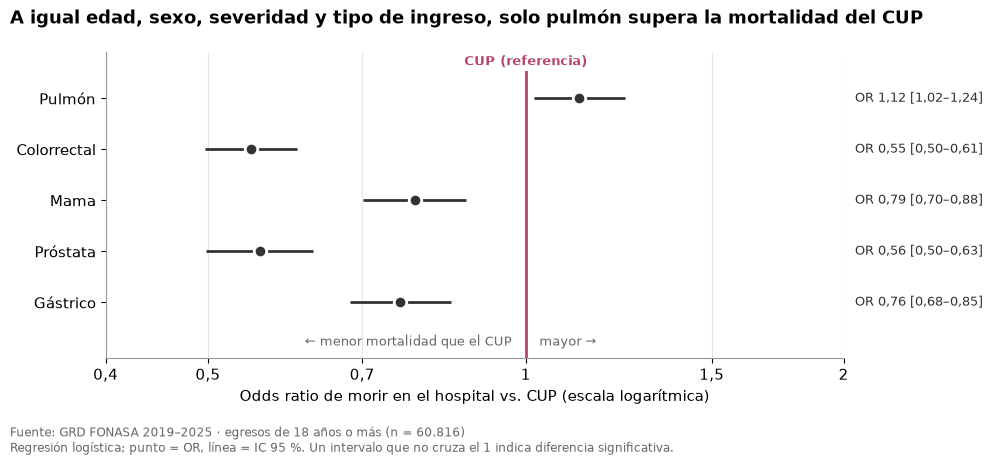

In [17]:
if 'modelo' in globals():
    filas_g = [f'C(GRUPO)[T.{g}]' for g in ORDEN[1:]]
    f = pd.DataFrame({'OR': np.exp(modelo.params[filas_g]), 'inf': np.exp(ic.loc[filas_g, 0]),
                      'sup': np.exp(ic.loc[filas_g, 1])})
    f.index = ORDEN[1:]
    yy = np.arange(len(f))[::-1]
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.axvline(1, color=COLOR_CUP, lw=2)
    ax.hlines(yy, f['inf'], f['sup'], color=TINTA, lw=2)
    ax.plot(f['OR'], yy, 'o', color=TINTA, markersize=9, markeredgecolor='white', markeredgewidth=2)
    for yi, (g, r) in zip(yy, f.iterrows()):
        ax.text(2.05, yi, f"OR {coma(r.OR, 2)} [{coma(r.inf, 2)}–{coma(r.sup, 2)}]", va='center',
                fontsize=9.5, color=TINTA)
    ax.set_xscale('log')
    ax.set_xticks([.4, .5, .7, 1, 1.5, 2], ['0,4', '0,5', '0,7', '1', '1,5', '2'])
    ax.minorticks_off()
    ax.set_xlim(.4, 2)
    ax.set_yticks(yy, f.index)
    ax.text(1, len(f) - .35, 'CUP (referencia)', color=COLOR_CUP, ha='center', fontsize=9.5, fontweight='bold',
            bbox=dict(facecolor='white', edgecolor='none', pad=2))
    ax.text(.97, -.85, '← menor mortalidad que el CUP', ha='right', fontsize=9, color='#666666')
    ax.text(1.03, -.85, 'mayor →', ha='left', fontsize=9, color='#666666')
    ax.set_ylim(-1.1, len(f) - .1)
    ax.set_xlabel('Odds ratio de morir en el hospital vs. CUP (escala logarítmica)')
    ax.grid(axis='x', color='#e5e5e5')
    ax.set_axisbelow(True)
    cerrar(fig, '06_mortalidad_ajustada_forest',
           'A igual edad, sexo, severidad y tipo de ingreso, solo pulmón supera la mortalidad del CUP',
           'Regresión logística; punto = OR, línea = IC 95 %. Un intervalo que no cruza el 1 indica diferencia significativa.')
else:
    print('Primero ejecuta la celda de la regresión (requiere statsmodels).')

**Interpretación:** con las cuatro variables controladas a la vez, los pacientes con cáncer **colorrectal** (OR 0,55) y de **próstata** (OR 0,56) metastásico tienen casi la mitad de las chances de morir en el hospital que un paciente con CUP, y los de **mama** y **gástrico** alrededor de un 20 % menos (OR ≈ 0,8). Ningún intervalo cruza el 1, así que todas las diferencias son significativas. Solo **pulmón** queda por encima del CUP (OR 1,12; IC 95 % 1,02–1,24), aunque la diferencia es pequeña. Entre las covariables, ingresar por urgencia multiplica por ≈5,6 las chances de morir y la severidad alta por ≈22 respecto de la baja.

## 8. Conclusiones preliminares
1. El CUP (C80.0) presenta una **mortalidad hospitalaria de ≈22 %**, comparable a la del cáncer de pulmón metastásico y entre 8 y 14 puntos mayor que la de los cánceres colorrectal, mama, gástrico y próstata metastásicos.
2. Los pacientes con CUP **ingresan mayoritariamente por urgencia** y con **alta severidad GRD**, lo que sugiere un diagnóstico en etapas avanzadas o en descompensación.
3. El CUP tiene la **estancia hospitalaria más larga** y un uso de pabellón menor que los cánceres quirúrgicos: consume recursos principalmente en días de cama.
4. La mayor mortalidad del CUP **no se explica solo por llegar más grave o más viejo**: se mantiene dentro de cada nivel de severidad GRD y de cada tramo de edad, y en la regresión logística ajustada por edad, sexo, severidad y tipo de ingreso los cánceres colorrectal, mama, próstata y gástrico tienen entre 21 % y 45 % menos chances de morir en el hospital que el CUP (OR 0,55–0,79). Solo pulmón queda por encima (OR 1,12).
5. **Limitaciones:** solo se conoce la mortalidad intrahospitalaria; la unidad es el egreso (un paciente puede tener varios); los diagnósticos 2–35 pueden ser antecedentes; la definición de *metastásico* depende de que la metástasis esté codificada; solo incluye hospitales públicos con GRD; en 2025 la edad es aproximada (tramos de 5 años) y se excluye el tramo 15–19; el ID cifrado del paciente no coincide entre 2020 y 2021 (0 pacientes en común), así que el conteo de pacientes únicos está sobreestimado.